Dataset: (600, 128, 128, 3), class counts: [200 200 200], device: cpu


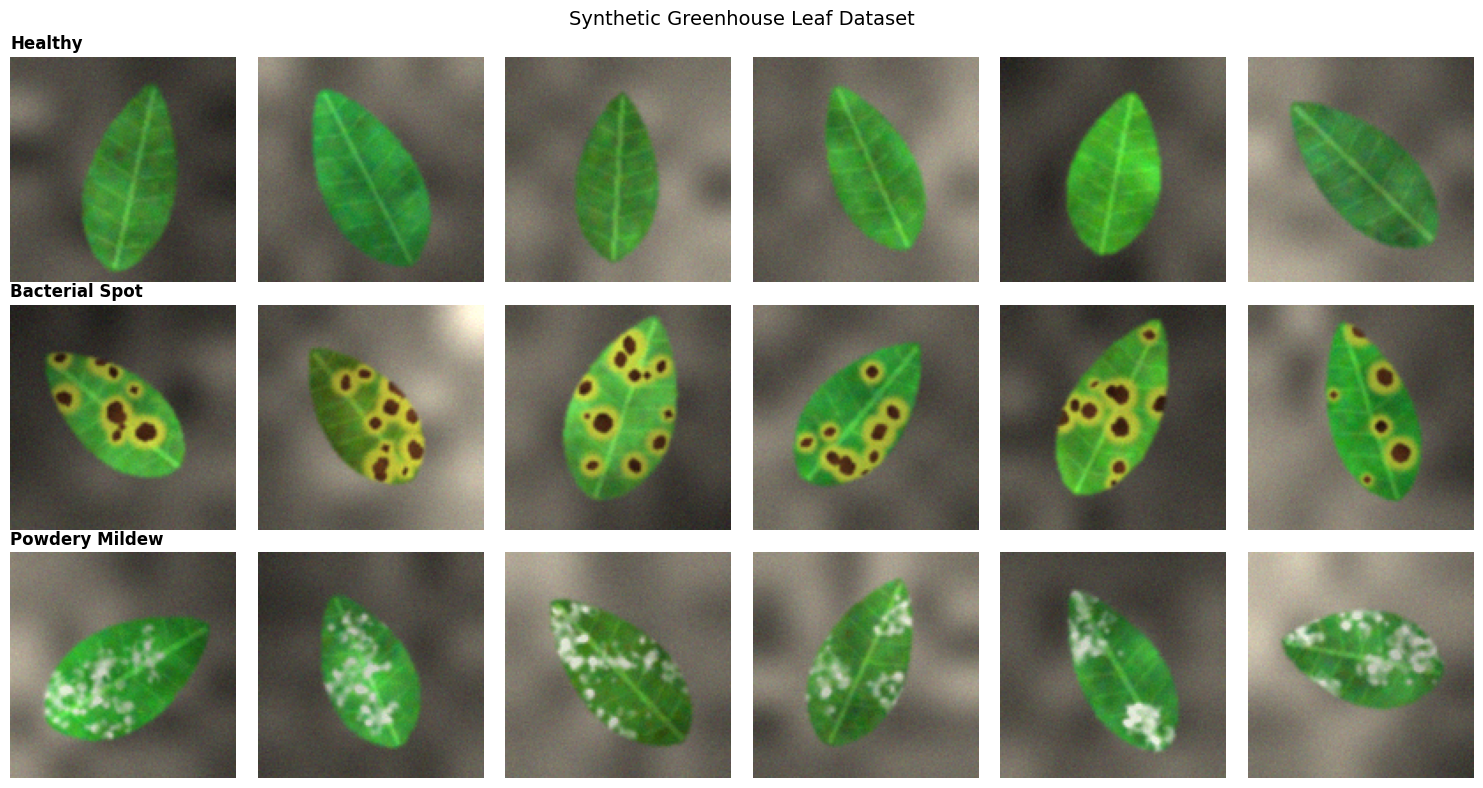

In [1]:
# ============================================================
# Cell 1 — Synthetic Leaf Image Generator
# ============================================================
import os, time, copy, random
import numpy as np, cv2, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASSES = ['Healthy', 'Bacterial Spot', 'Powdery Mildew']


class SyntheticLeafGenerator:
    """Procedural generator of realistic greenhouse-camera leaf images (RGB uint8 + lesion masks)."""

    def __init__(self, img_size=128, n_per_class=200, seed=SEED):
        self.S, self.n = img_size, n_per_class
        self.rng = np.random.default_rng(seed)

    def _smooth_noise(self, grid=8, ch=1):
        z = self.rng.normal(0, 1, (grid, grid, ch)).astype(np.float32)
        z = cv2.resize(z, (self.S, self.S), interpolation=cv2.INTER_CUBIC)
        return z.reshape(self.S, self.S, ch)

    def _background(self):  # low-saturation greenhouse bench / soil
        g = self.rng.uniform(70, 130)
        bg = np.full((self.S, self.S, 3), g, np.float32) * np.array([1.0, 0.95, 0.85], np.float32)
        return bg * (1 + 0.15 * self._smooth_noise(6))

    def _leaf_geometry(self):
        S, r = self.S, self.rng
        L, W = r.uniform(0.36, 0.44) * S, r.uniform(0.17, 0.23) * S
        a = r.uniform(0, np.pi)                                   # random rotation
        c = S / 2 + r.uniform(-6, 6, 2)
        d, p = np.array([np.cos(a), np.sin(a)]), np.array([-np.sin(a), np.cos(a)])
        width = lambda u: W * np.clip(1 - u ** 2, 0, 1) ** 0.7 * (1 + 0.25 * u)
        u = np.linspace(-1, 1, 80)
        top = c + np.outer(u * L, d) + np.outer(width(u), p)
        bot = c + np.outer(u[::-1] * L, d) - np.outer(width(u[::-1]), p)
        mask = np.zeros((S, S), np.uint8)
        cv2.fillPoly(mask, [np.vstack([top, bot]).astype(np.int32)], 255)
        return mask, c, d, p, L, width

    def _veins(self, c, d, p, L, width):
        v = np.zeros((self.S, self.S), np.float32)
        pt = lambda q: tuple(int(round(t)) for t in q)
        cv2.line(v, pt(c - 0.95 * L * d), pt(c + 0.95 * L * d), 1.0, 2)          # midrib
        for u in np.linspace(-0.75, 0.75, 7):                                       # lateral veins
            base = c + u * L * d
            for s in (-1, 1):
                end = base + s * 0.85 * width(u) * p - 0.3 * width(u) * d
                cv2.line(v, pt(base), pt(end), 0.7, 1)
        return cv2.GaussianBlur(v, (3, 3), 0)

    def _bacterial_spot(self, img, mask):
        ys, xs = np.nonzero(mask)
        halo, core = np.zeros(mask.shape, np.float32), np.zeros(mask.shape, np.float32)
        for _ in range(self.rng.integers(6, 18)):
            i = self.rng.integers(len(ys)); cx, cy = int(xs[i]), int(ys[i])
            r = self.rng.uniform(2, 5.5)
            cv2.circle(halo, (cx, cy), int(r * 2.0), 1.0, -1)
            axes = (int(r), max(1, int(r * self.rng.uniform(0.6, 1.0))))
            cv2.ellipse(core, (cx, cy), axes, self.rng.uniform(0, 180), 0, 360, 1.0, -1)
        halo = cv2.GaussianBlur(halo, (7, 7), 0)[..., None] * 0.75
        core = cv2.GaussianBlur(core, (3, 3), 0)[..., None]
        img = img * (1 - halo) + np.array([215, 200, 60], np.float32) * halo          # chlorotic yellow halo
        dark = np.array([70, 40, 20], np.float32) * (1 + 0.2 * self._smooth_noise(16))
        img = img * (1 - core) + dark * core                                          # necrotic brown core
        return img, np.maximum(halo[..., 0] / 0.75, core[..., 0])

    def _powdery_mildew(self, img, mask):
        ys, xs = np.nonzero(mask)
        pw = np.zeros(mask.shape, np.float32)
        for _ in range(self.rng.integers(4, 10)):                                     # fungal colonies
            i = self.rng.integers(len(ys)); cx, cy = xs[i], ys[i]
            spread = self.rng.uniform(3, 9)
            for _ in range(self.rng.integers(15, 40)):
                x, y = self.rng.normal([cx, cy], spread)
                cv2.circle(pw, (int(x), int(y)), int(self.rng.integers(1, 4)), float(self.rng.uniform(0.5, 1)), -1)
        pw = cv2.GaussianBlur(pw, (5, 5), 0)
        pw = np.clip(pw * (0.8 + 0.4 * self._smooth_noise(32)[..., 0]), 0, 0.9)[..., None]
        white = np.array([228, 228, 218], np.float32) - self.rng.uniform(0, 30)
        return img * (1 - pw) + white * pw, pw[..., 0]

    def render(self, label):
        S = self.S
        mask, c, d, p, L, width = self._leaf_geometry()
        base = np.array([self.rng.uniform(40, 80), self.rng.uniform(115, 170), self.rng.uniform(30, 60)], np.float32)
        leaf = base * (1 + 0.12 * self._smooth_noise(8)) + 6 * self._smooth_noise(32, 3)   # tissue texture
        leaf += self._veins(c, d, p, L, width)[..., None] * np.array([30, 40, 20], np.float32)
        lesion = np.zeros((S, S), np.float32)
        if label == 1:   leaf, lesion = self._bacterial_spot(leaf, mask)
        elif label == 2: leaf, lesion = self._powdery_mildew(leaf, mask)
        m = cv2.GaussianBlur(mask.astype(np.float32) / 255, (5, 5), 0)[..., None]
        img = self._background() * (1 - m) + leaf * m
        yy, xx = np.mgrid[-1:1:S * 1j, -1:1:S * 1j]                                    # directional lighting
        th = self.rng.uniform(0, 2 * np.pi)
        img *= (1 + self.rng.uniform(0.15, 0.35) * (np.cos(th) * xx + np.sin(th) * yy))[..., None]
        img += self.rng.normal(0, 5, img.shape)                                         # sensor noise
        return np.clip(img, 0, 255).astype(np.uint8), ((lesion * (mask > 0)) > 0.3).astype(np.uint8)

    def generate(self):
        X, Y, M = [], [], []
        for label in range(len(CLASSES)):
            for _ in range(self.n):
                img, les = self.render(label); X.append(img); Y.append(label); M.append(les)
        idx = self.rng.permutation(len(X))
        return np.stack(X)[idx], np.array(Y)[idx], np.stack(M)[idx]


X_raw, y_all, lesion_masks = SyntheticLeafGenerator().generate()
print(f'Dataset: {X_raw.shape}, class counts: {np.bincount(y_all)}, device: {DEVICE}')

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for c in range(3):
    for j, i in enumerate(np.where(y_all == c)[0][:6]):
        axes[c, j].imshow(X_raw[i]); axes[c, j].axis('off')
    axes[c, 0].set_title(CLASSES[c], loc='left', fontweight='bold')
plt.suptitle('Synthetic Greenhouse Leaf Dataset', fontsize=14); plt.tight_layout(); plt.show()

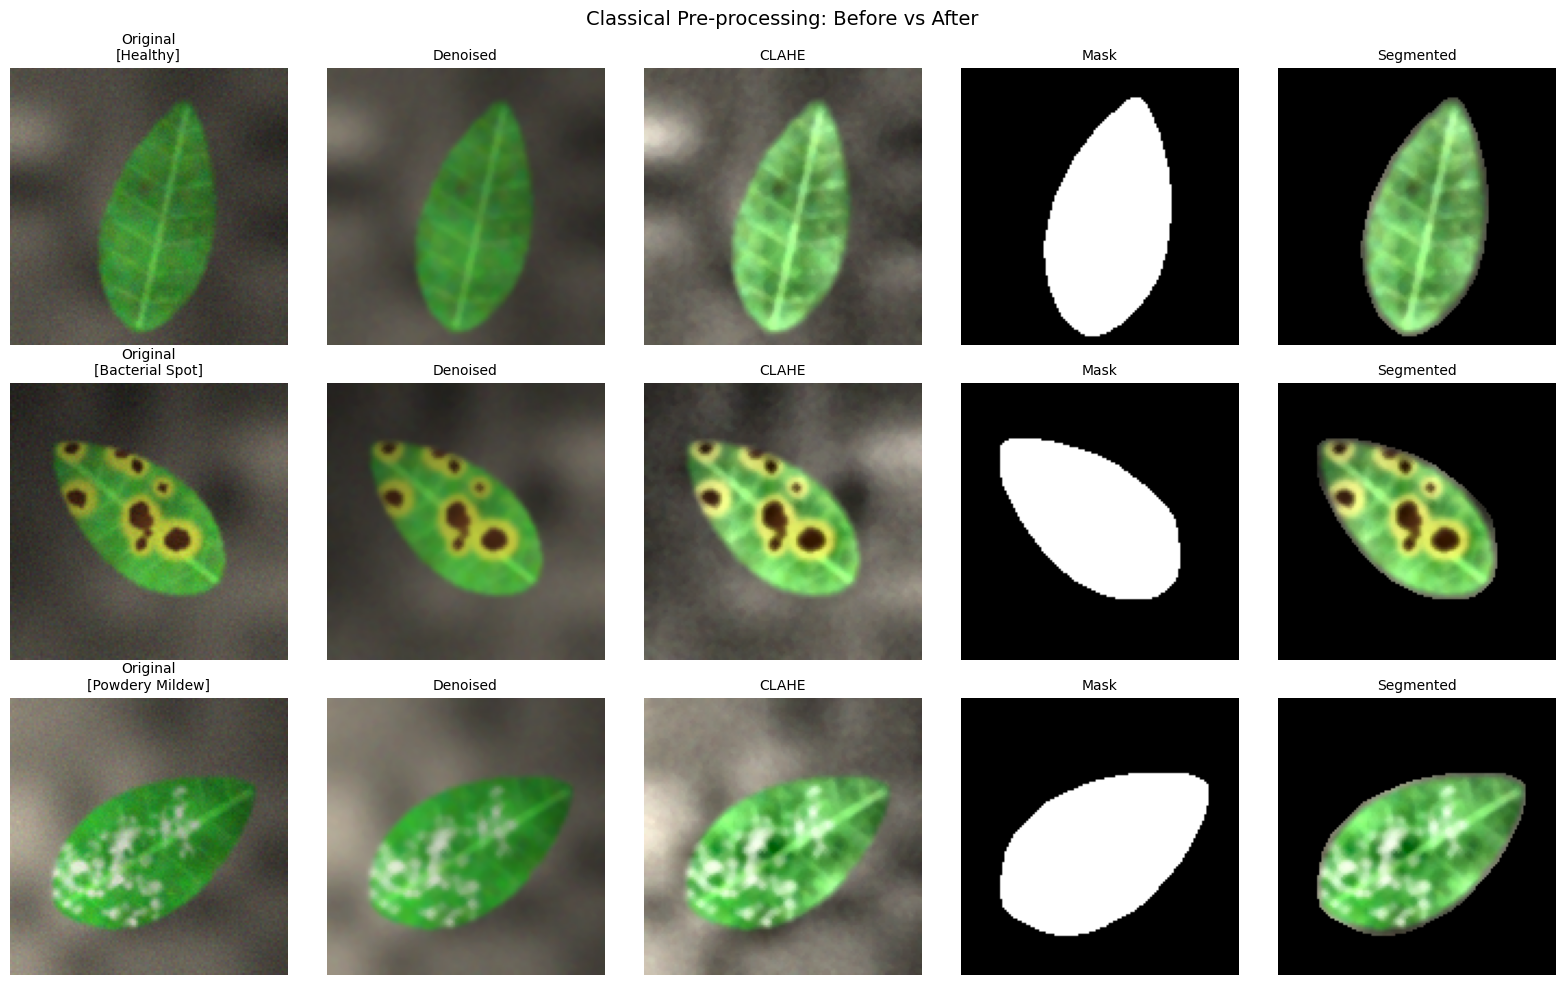

In [2]:
# ============================================================
# Cell 2 — Classical Image Processing Pipeline
# ============================================================
class ClassicalPreprocessor:
    """Denoise -> CLAHE contrast enhancement -> HSV leaf segmentation + morphology."""

    def __init__(self, clip=2.0, tile=8, kernel=5, hsv_lo=(25, 40, 30), hsv_hi=(95, 255, 255)):
        self.clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
        self.ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel, kernel))
        self.lo, self.hi = hsv_lo, hsv_hi

    def denoise(self, img):
        return cv2.medianBlur(cv2.GaussianBlur(img, (3, 3), 0), 3)

    def enhance(self, img):  # CLAHE on the L channel only (keeps colour fidelity)
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        lab[..., 0] = self.clahe.apply(lab[..., 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    def segment(self, img):
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
        m = cv2.inRange(hsv, self.lo, self.hi)
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, self.ker)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, self.ker, iterations=2)
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        full = np.zeros_like(m)
        if cnts:  # convex hull of largest blob -> lesions (brown/white) stay inside the mask
            cv2.drawContours(full, [cv2.convexHull(max(cnts, key=cv2.contourArea))], -1, 255, cv2.FILLED)
        return full

    def __call__(self, img, return_steps=False):
        d = self.denoise(img); e = self.enhance(d); m = self.segment(e)
        out = cv2.bitwise_and(e, e, mask=m)
        return dict(Original=img, Denoised=d, CLAHE=e, Mask=m, Segmented=out) if return_steps else out


prep = ClassicalPreprocessor()
X_proc = np.stack([prep(x) for x in X_raw])

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for r, c in enumerate(range(3)):
    steps = prep(X_raw[np.where(y_all == c)[0][0]], return_steps=True)
    for k, (name, im) in enumerate(steps.items()):
        axes[r, k].imshow(im, cmap='gray' if im.ndim == 2 else None); axes[r, k].axis('off')
        axes[r, k].set_title(f'{name}' + (f'\n[{CLASSES[c]}]' if k == 0 else ''), fontsize=10)
plt.suptitle('Classical Pre-processing: Before vs After', fontsize=14); plt.tight_layout(); plt.show()

Trainable parameters: 58,563
Epoch 01/15 | loss train/val 0.7181/1.1948 | acc train/val 0.762/0.333
Epoch 02/15 | loss train/val 0.2586/2.2548 | acc train/val 0.988/0.333
Epoch 03/15 | loss train/val 0.2041/0.5452 | acc train/val 1.000/0.783
Epoch 04/15 | loss train/val 0.2038/0.1979 | acc train/val 1.000/1.000
Epoch 05/15 | loss train/val 0.1922/0.1873 | acc train/val 1.000/1.000
Epoch 06/15 | loss train/val 0.1869/0.1865 | acc train/val 1.000/1.000
Epoch 07/15 | loss train/val 0.1914/0.1855 | acc train/val 1.000/1.000
Epoch 08/15 | loss train/val 0.1852/0.1819 | acc train/val 1.000/1.000
Epoch 09/15 | loss train/val 0.1877/0.1812 | acc train/val 1.000/1.000
Epoch 10/15 | loss train/val 0.1852/0.1802 | acc train/val 1.000/1.000
Epoch 11/15 | loss train/val 0.1836/0.1802 | acc train/val 1.000/1.000
Epoch 12/15 | loss train/val 0.1834/0.1796 | acc train/val 1.000/1.000
Epoch 13/15 | loss train/val 0.1828/0.1796 | acc train/val 1.000/1.000
Epoch 14/15 | loss train/val 0.1856/0.1792 | acc

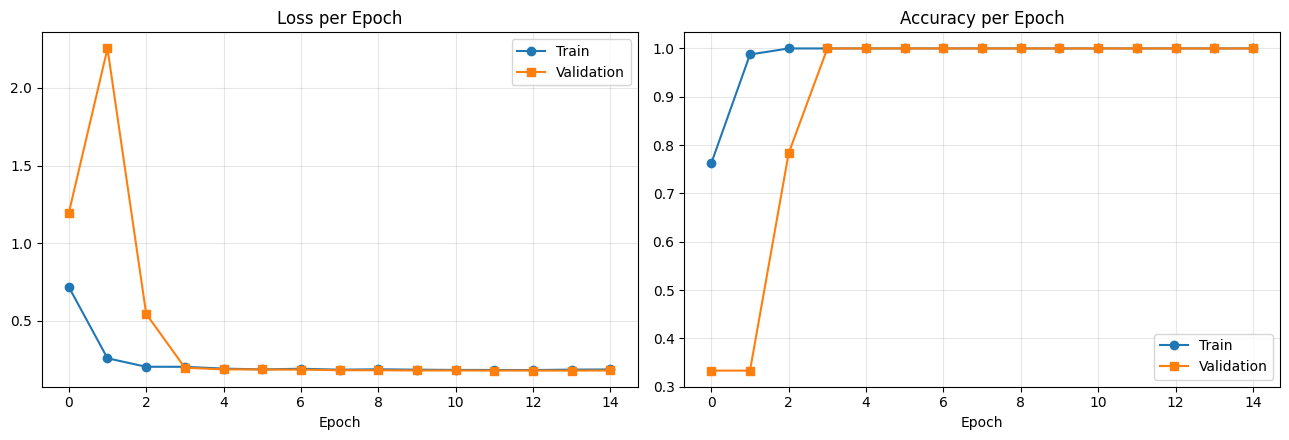

In [3]:
# ============================================================
# Cell 3 — Lightweight Edge-CNN (Depthwise Separable) + Training
# ============================================================
from sklearn.model_selection import train_test_split

class DSConv(nn.Module):
    """Depthwise 3x3 + Pointwise 1x1, each followed by BatchNorm + ReLU."""
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cin, 3, stride, 1, groups=cin, bias=False), nn.BatchNorm2d(cin), nn.ReLU(),
            nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU())
    def forward(self, x): return self.block(x)


class EdgeLeafNet(nn.Module):
    def __init__(self, n_classes=3, c=(16, 32, 64, 128, 160)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, c[0], 3, 2, 1, bias=False), nn.BatchNorm2d(c[0]), nn.ReLU())  # 64x64
        self.features = nn.Sequential(
            DSConv(c[0], c[1]), DSConv(c[1], c[2], 2), DSConv(c[2], c[2]),       # 32x32
            DSConv(c[2], c[3], 2), DSConv(c[3], c[3]), DSConv(c[3], c[4]))       # 16x16 (Grad-CAM layer)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.2), nn.Linear(c[4], n_classes))
    def forward(self, x): return self.head(self.gap(self.features(self.stem(x))))
    @property
    def target_layer(self): return self.features[-1]


def to_tensor(arr):
    return (torch.from_numpy(arr).permute(0, 3, 1, 2).float() / 255 - 0.5) / 0.5

idx_tr, idx_va = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=SEED)
train_dl = DataLoader(TensorDataset(to_tensor(X_proc[idx_tr]), torch.from_numpy(y_all[idx_tr])), batch_size=32, shuffle=True)
val_dl = DataLoader(TensorDataset(to_tensor(X_proc[idx_va]), torch.from_numpy(y_all[idx_va])), batch_size=64)


class Trainer:
    def __init__(self, model, lr=3e-3, epochs=15):
        self.model, self.epochs = model.to(DEVICE), epochs
        self.opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        self.sched = torch.optim.lr_scheduler.CosineAnnealingLR(self.opt, T_max=epochs)
        self.crit = nn.CrossEntropyLoss(label_smoothing=0.05)
        self.hist = {k: [] for k in ['tr_loss', 'va_loss', 'tr_acc', 'va_acc']}

    @staticmethod
    def augment(x):  # on-the-fly flips & 90-degree rotations (camera-orientation invariance)
        if random.random() < 0.5: x = x.flip(3)
        if random.random() < 0.5: x = x.flip(2)
        return torch.rot90(x, random.randint(0, 3), (2, 3))

    def run_epoch(self, dl, train):
        self.model.train(train); tot, correct, loss_sum = 0, 0, 0.0
        with torch.set_grad_enabled(train):
            for xb, yb in dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                if train: xb = self.augment(xb)
                out = self.model(xb); loss = self.crit(out, yb)
                if train: self.opt.zero_grad(); loss.backward(); self.opt.step()
                loss_sum += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); tot += len(yb)
        return loss_sum / tot, correct / tot

    def fit(self, tr, va):
        best = 0.0
        for ep in range(1, self.epochs + 1):
            trl, tra = self.run_epoch(tr, True); val, vaa = self.run_epoch(va, False); self.sched.step()
            for k, v in zip(self.hist, (trl, val, tra, vaa)): self.hist[k].append(v)
            if vaa >= best: best, self.best_state = vaa, copy.deepcopy(self.model.state_dict())
            print(f'Epoch {ep:02d}/{self.epochs} | loss train/val {trl:.4f}/{val:.4f} | acc train/val {tra:.3f}/{vaa:.3f}')
        self.model.load_state_dict(self.best_state)
        return self.hist


model = EdgeLeafNet(len(CLASSES))
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')
hist = Trainer(model, epochs=15).fit(train_dl, val_dl)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, key, name in [(ax[0], 'loss', 'Loss'), (ax[1], 'acc', 'Accuracy')]:
    a.plot(hist[f'tr_{key}'], 'o-', label='Train'); a.plot(hist[f'va_{key}'], 's-', label='Validation')
    a.set_title(f'{name} per Epoch'); a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

Pointing-Game accuracy (CAM peak on lesion): 41.2%
Mean CAM energy inside lesions: 36.7%


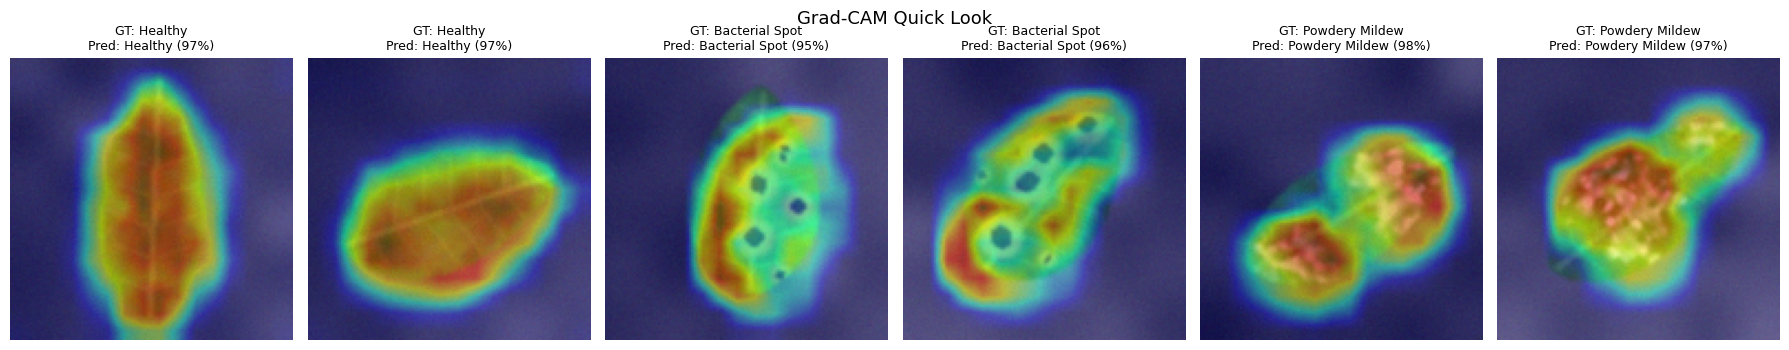

In [4]:
# ============================================================
# Cell 4 — Grad-CAM Visual Explanation
# ============================================================
class GradCAM:
    """Gradient-weighted Class Activation Mapping on a chosen conv layer."""
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self.acts = out
        if out.requires_grad: out.register_hook(lambda g: setattr(self, 'grads', g))

    def __call__(self, x, cls=None):
        self.model.eval()
        logits = self.model(x); probs = F.softmax(logits, 1)
        cls = int(logits.argmax(1)) if cls is None else cls
        self.model.zero_grad(); logits[0, cls].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)                 # alpha_k^c = GAP of gradients
        cam = F.relu((weights * self.acts).sum(1, keepdim=True))            # ReLU(sum_k alpha_k * A^k)
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), cls, probs[0, cls].item()

    def remove(self): self.handle.remove()


def cam_overlay(img, cam, alpha=0.45):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8((1 - alpha) * img + alpha * heat)


gradcam = GradCAM(model, model.target_layer)

# Explanation faithfulness: does the CAM look at the real lesions? (ground-truth lesion masks from Cell 1)
hits, energy = [], []
for i in idx_va[y_all[idx_va] > 0]:
    cam, _, _ = gradcam(to_tensor(X_proc[i:i + 1]).to(DEVICE), cls=int(y_all[i]))
    les = cv2.dilate(lesion_masks[i], np.ones((5, 5), np.uint8))
    hits.append(les[np.unravel_index(cam.argmax(), cam.shape)] > 0)
    energy.append((cam * les).sum() / (cam.sum() + 1e-8))
print(f'Pointing-Game accuracy (CAM peak on lesion): {np.mean(hits):.1%}')
print(f'Mean CAM energy inside lesions: {np.mean(energy):.1%}')

demo = [i for c in range(3) for i in idx_va[y_all[idx_va] == c][:2]]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, i in zip(axes, demo):
    cam, pc, conf = gradcam(to_tensor(X_proc[i:i + 1]).to(DEVICE))
    ax.imshow(cam_overlay(X_raw[i], cam)); ax.axis('off')
    ax.set_title(f'GT: {CLASSES[y_all[i]]}\nPred: {CLASSES[pc]} ({conf:.0%})', fontsize=9)
plt.suptitle('Grad-CAM Quick Look', fontsize=13); plt.tight_layout(); plt.show()

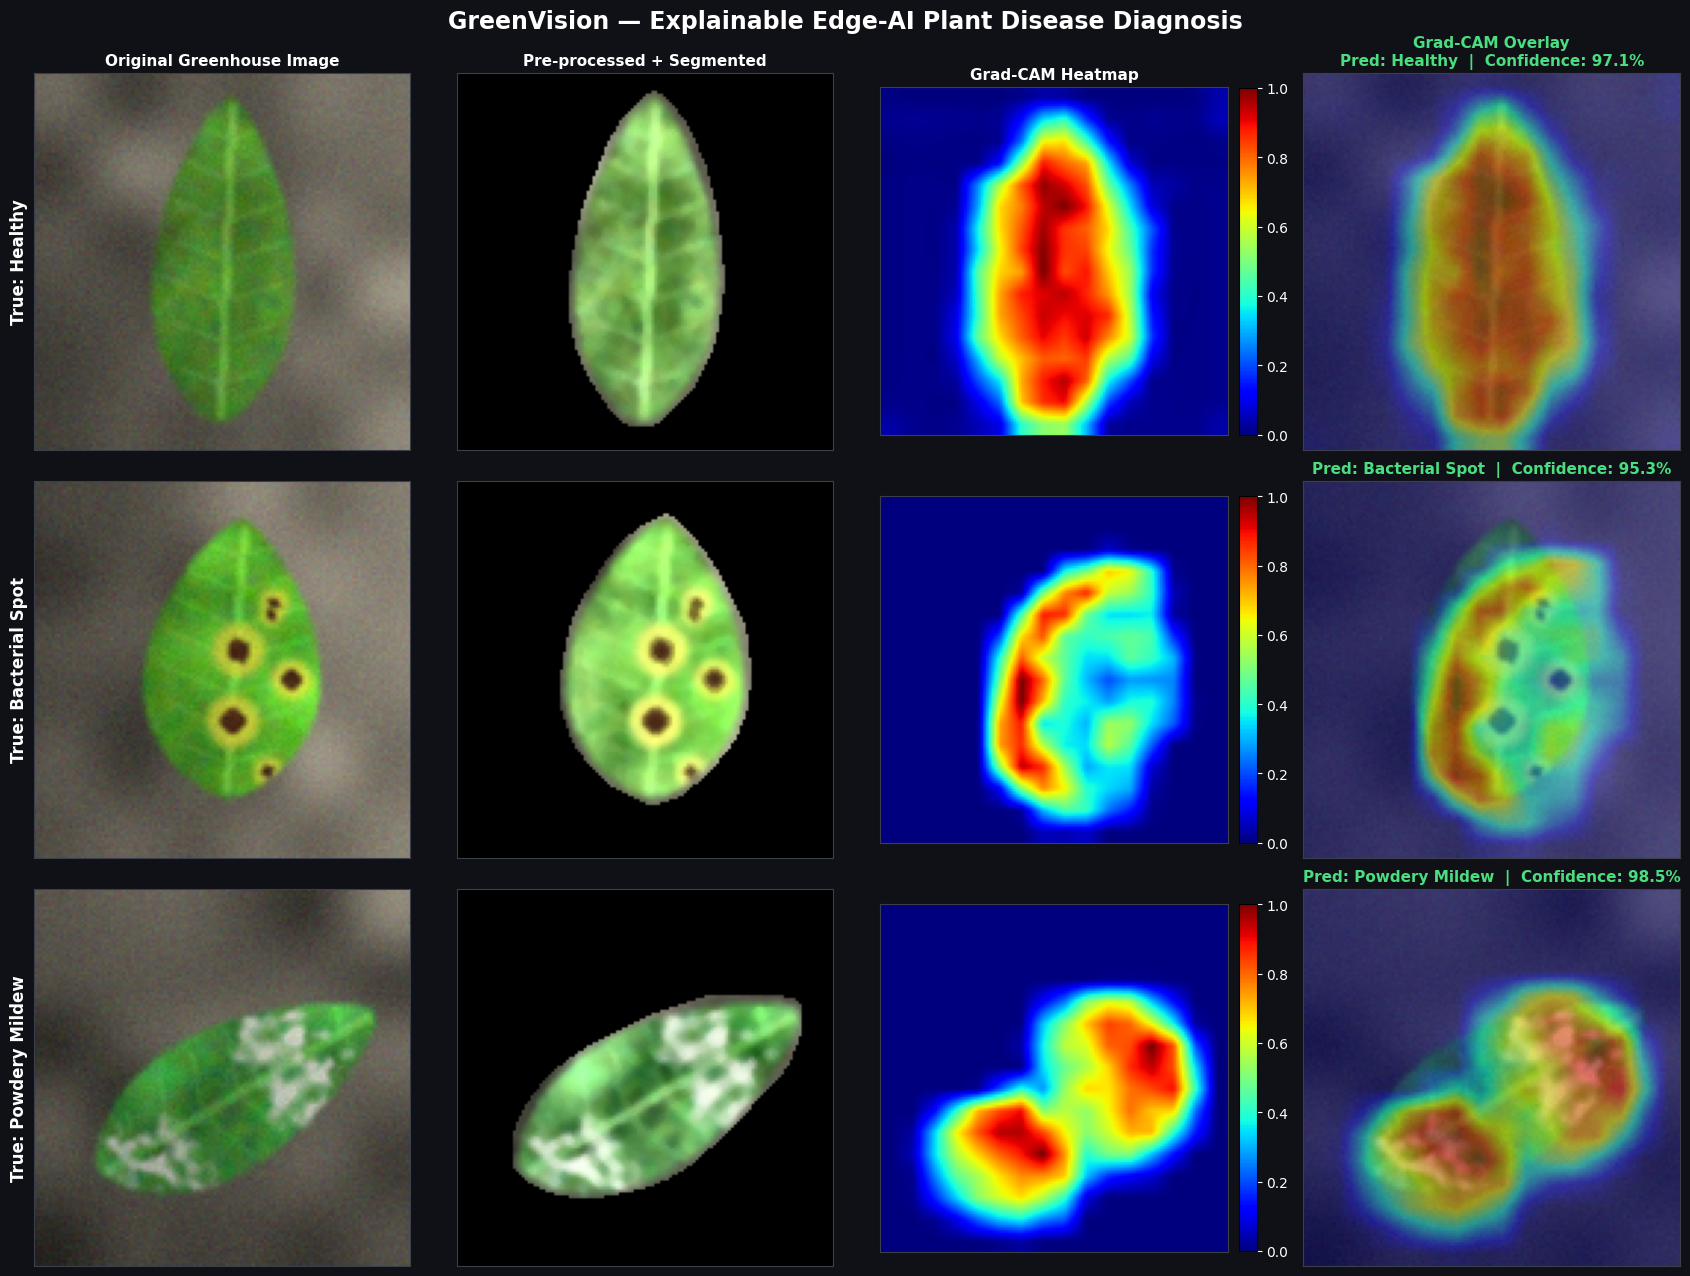

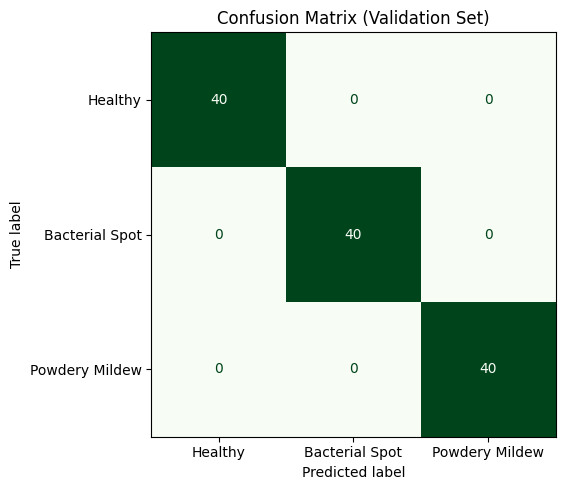

                precision    recall  f1-score   support

       Healthy      1.000     1.000     1.000        40
Bacterial Spot      1.000     1.000     1.000        40
Powdery Mildew      1.000     1.000     1.000        40

      accuracy                          1.000       120
     macro avg      1.000     1.000     1.000       120
  weighted avg      1.000     1.000     1.000       120


        GreenVision — Edge Deployment Evaluation Report
                                Metric    Value
                      Model Parameters   58,563
                     Model Size (FP32) 0.257 MB
                        Compute (MACs)  23.90 M
Inference Latency (median, 1 CPU core)  8.02 ms
               Inference Latency (p95) 30.11 ms
                            Throughput  125 FPS
                   Validation Accuracy  100.00%
                        Macro F1-Score   1.0000
                Grad-CAM Pointing Game    41.2%
Saved: gradcam_results.png, greenvision_edge.pt


In [5]:
# ============================================================
# Cell 5 — Final Dashboard + Edge Hardware Profiler
# ============================================================
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report, accuracy_score

model.eval()
with torch.no_grad():
    probs_va = F.softmax(model(to_tensor(X_proc[idx_va]).to(DEVICE)), 1).cpu().numpy()
y_true, y_pred = y_all[idx_va], probs_va.argmax(1)

picks = []  # one (preferably correctly classified) validation sample per class
for c in range(3):
    cand = np.where((y_true == c) & (y_pred == c))[0]
    picks.append(idx_va[(cand if len(cand) else np.where(y_true == c)[0])[0]])

# ---------- 1) 4-column Grad-CAM dashboard ----------
BG, FG = '#0f1117', 'white'
cols = ['Original Greenhouse Image', 'Pre-processed + Segmented', 'Grad-CAM Heatmap', 'Grad-CAM Overlay']
fig, axes = plt.subplots(3, 4, figsize=(17, 13), facecolor=BG)
for r, i in enumerate(picks):
    cam, pc, conf = gradcam(to_tensor(X_proc[i:i + 1]).to(DEVICE))
    panels = [X_raw[i], X_proc[i], cam, cam_overlay(X_raw[i], cam)]
    for c, (ax, pnl) in enumerate(zip(axes[r], panels)):
        if c == 2:
            im = ax.imshow(pnl, cmap='jet', vmin=0, vmax=1)
            cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.ax.tick_params(colors=FG)
        else:
            ax.imshow(pnl)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_color('#3a3f4b')
        title = cols[c] if r == 0 else ''
        if c == 3:
            ok = pc == y_all[i]
            title += ('\n' if title else '') + f'Pred: {CLASSES[pc]}  |  Confidence: {conf * 100:.1f}%'
            ax.set_title(title, color='#4ade80' if ok else '#f87171', fontsize=11, fontweight='bold')
        else:
            ax.set_title(title, color=FG, fontsize=11, fontweight='bold')
    axes[r, 0].set_ylabel(f'True: {CLASSES[y_all[i]]}', color=FG, fontsize=12, fontweight='bold')
fig.suptitle('GreenVision — Explainable Edge-AI Plant Disease Diagnosis', color=FG, fontsize=17, fontweight='bold')
plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=300, bbox_inches='tight', facecolor=BG)
plt.show()

# ---------- 2) Confusion matrix + classification report ----------
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(cmap='Greens', ax=ax, colorbar=False)
ax.set_title('Confusion Matrix (Validation Set)'); plt.tight_layout(); plt.show()
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))


class EdgeProfiler:
    """Simulates single-core CPU deployment (Raspberry-Pi-like) and reports edge metrics."""
    def __init__(self, state_dict, input_size=(1, 3, 128, 128)):
        self.model = EdgeLeafNet(len(CLASSES))
        self.model.load_state_dict({k: v.cpu() for k, v in state_dict.items()}); self.model.eval()
        self.x = torch.randn(*input_size)

    def n_params(self): return sum(p.numel() for p in self.model.parameters())

    def size_mb(self, path='greenvision_edge.pt'):
        torch.save(self.model.state_dict(), path); return os.path.getsize(path) / 1024 ** 2

    @torch.no_grad()
    def macs_m(self):
        total = [0]
        def hook(m, i, o):
            if isinstance(m, nn.Conv2d): total[0] += o.numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
            else: total[0] += m.in_features * m.out_features
        hs = [m.register_forward_hook(hook) for m in self.model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
        self.model(self.x)
        for h in hs: h.remove()
        return total[0] / 1e6

    @torch.no_grad()
    def latency_ms(self, runs=200, warmup=20):
        n_thr = torch.get_num_threads(); torch.set_num_threads(1)
        for _ in range(warmup): self.model(self.x)
        t = []
        for _ in range(runs):
            t0 = time.perf_counter(); self.model(self.x); t.append((time.perf_counter() - t0) * 1e3)
        torch.set_num_threads(n_thr)
        return np.median(t), np.percentile(t, 95)


prof = EdgeProfiler(model.state_dict())
med, p95 = prof.latency_ms()
report = pd.DataFrame({
    'Metric': ['Model Parameters', 'Model Size (FP32)', 'Compute (MACs)', 'Inference Latency (median, 1 CPU core)',
               'Inference Latency (p95)', 'Throughput', 'Validation Accuracy', 'Macro F1-Score',
               'Grad-CAM Pointing Game'],
    'Value': [f'{prof.n_params():,}', f'{prof.size_mb():.3f} MB', f'{prof.macs_m():.2f} M', f'{med:.2f} ms',
              f'{p95:.2f} ms', f'{1000 / med:.0f} FPS', f'{accuracy_score(y_true, y_pred):.2%}',
              f'{f1_score(y_true, y_pred, average="macro"):.4f}', f'{np.mean(hits):.1%}']})
print('\n' + '=' * 62 + '\n        GreenVision — Edge Deployment Evaluation Report\n' + '=' * 62)
print(report.to_string(index=False))
print('=' * 62 + '\nSaved: gradcam_results.png, greenvision_edge.pt')